In [3]:
import sys
!uv pip install distinctipy --python {sys.executable}

Resolved 2 packages in 244ms                                         
Prepared 1 package in 79ms                                               
Installed 2 packages in 3.12s                               
 + distinctipy==1.3.4
 + numpy==2.2.6


In [9]:
import scanpy as sc
import matplotlib.pyplot as plt

# Nature figure settings
sc.set_figure_params(
    dpi=300,
    dpi_save=600,
    fontsize=7,
    figsize=(7, 7),
    frameon=False,
    vector_friendly=True,
)
plt.rcParams.update({
    "font.family": "Arial",
    "pdf.fonttype": 42,       # editable text in PDF (Nature requirement)
    "ps.fonttype": 42,
    "axes.linewidth": 0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
})

In [5]:
# pip install distinctipy
from distinctipy import distinctipy

colors = distinctipy.get_colors(170, pastel_factor=0.0)
palette = ["#" + "".join(f"{int(c*255):02x}" for c in rgb) for rgb in colors]

In [6]:
import scanpy as sc

In [7]:
adata_merfish = sc.read_h5ad('/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/mmb0-1b_smb1-1b_1p/harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad')

In [14]:
adata_starmap = sc.read_h5ad('/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/mmb0-1b_smb1-1b_1p/harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad')

/tmp/ipykernel_2563799/474385156.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


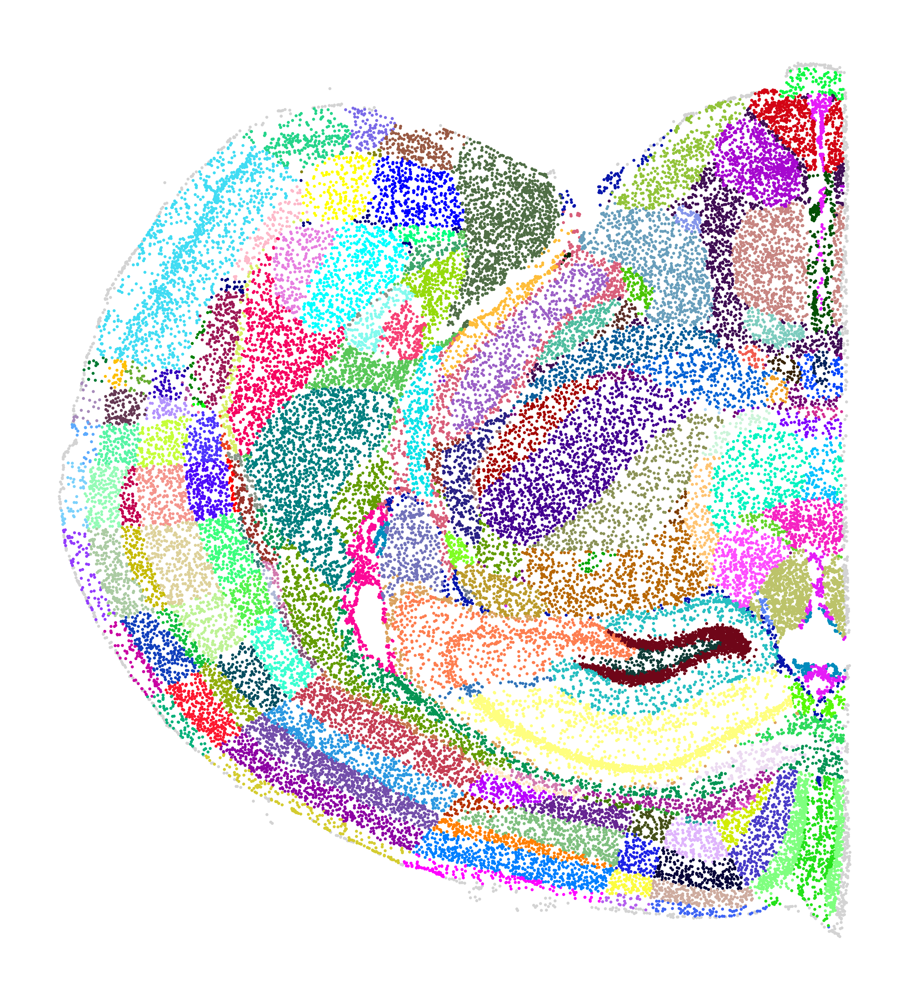

In [11]:
adata_merfish.uns["ccf_region_name_colors"] = palette

fig, ax = plt.subplots(1, 1, figsize=(7, 7))
sc.pl.spatial(
    adata_merfish,
    color="ccf_region_name",
    spot_size=20,
    legend_loc=None,
    show=False,
    ax=ax,
)
ax.set_title("")
ax.axis("off")

fig.savefig("spatial_ccf_regions.pdf", bbox_inches="tight", pad_inches=0.05, dpi=300)
fig.savefig("spatial_ccf_regions.png", bbox_inches="tight", pad_inches=0.05, dpi=300)
plt.show()

In [16]:
adata_starmap.obs['Sub_molecular_tissue_region'].value_counts()

Sub_molecular_tissue_region
TH_2         3192
FT_1         2220
CNU_9        1873
CTX_A_3      1746
TH_4         1618
             ... 
CNU_7          53
MB_P_MY_9      51
CNU_5          46
HY_4           19
CTX_B_9         2
Name: count, Length: 63, dtype: int64

/tmp/ipykernel_2563799/174746676.py:4: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(


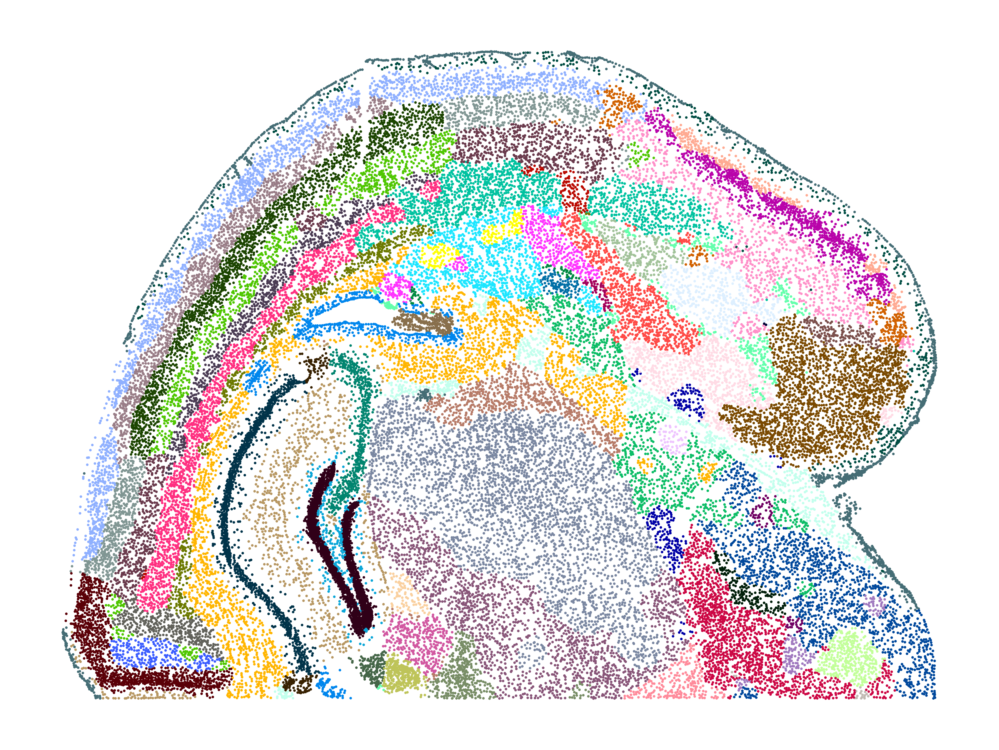

In [17]:
adata_starmap.uns["Sub_molecular_tissue_region"] = palette

fig, ax = plt.subplots(1, 1, figsize=(7, 7))
sc.pl.spatial(
    adata_starmap,
    color="Sub_molecular_tissue_region",
    spot_size=100,
    legend_loc=None,
    show=False,
    ax=ax,
)
ax.set_title("")
ax.axis("off")

fig.savefig("sub_molecular_tissue_region.pdf", bbox_inches="tight", pad_inches=0.05, dpi=300)
fig.savefig("sub_molecular_tissue_region.png", bbox_inches="tight", pad_inches=0.05, dpi=300)
plt.show()

In [94]:
import numpy as np
import anndata as ad

In [95]:
ad.settings.allow_write_nullable_strings = True

In [96]:
adata_merfish = sc.read_h5ad('/nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_2p/harmonised_merfish_mouse_brain_239-batch_batch82.h5ad')
adata_merfish.write('/nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_xmb2-1b_3p/harmonised_merfish_mouse_brain_239-batch_batch82.h5ad')
adata_merfish

AnnData object with n_obs × n_vars = 49179 × 1085
    obs: 'donor_id', 'brain_section_label', 'major_brain_region', 'ccf_region_name', 'cell_type', 'cell_id', 'nichecompass_latent_cluster'
    var: 'ensembl_id'
    uns: 'age_group', 'age_num', 'age_unit', 'assay', 'batch', 'citation', 'dataset_id', 'disease_level1', 'disease_level2', 'disease_level3', 'log1p', 'sample', 'schema_reference', 'schema_version', 'sex', 'species', 'study', 'tissue', 'title'
    obsm: 'X_CCF', 'X_umap', 'spatial'

In [97]:
adata_starmap = sc.read_h5ad('/nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_2p/harmonised_starmap_plus_mouse_cns_batch15.h5ad')
adata_starmap.write('/nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_xmb2-1b_3p/harmonised_starmap_plus_mouse_cns_batch15.h5ad')
adata_starmap

AnnData object with n_obs × n_vars = 43341 × 1015
    obs: 'Main_molecular_cell_type', 'Sub_molecular_cell_type', 'Main_molecular_tissue_region', 'Sub_molecular_tissue_region', 'Molecular_spatial_cell_type', 'dataset', 'cell_type', 'cell_type_ontology_term_id', 'n_genes', 'cell_id', 'nichecompass_latent_cluster'
    var: 'ensembl_id'
    uns: 'age_group', 'age_num', 'age_unit', 'assay', 'batch', 'dataset_id', 'disease_level1', 'disease_level2', 'disease_level3', 'log1p', 'sample', 'sex', 'species', 'study', 'tissue'
    obsm: 'spatial'

In [98]:
adata_xenium = sc.read_h5ad('/nfs/team361/sb75/DATASETS/silver/xmb2-6b_1p/Xenium_V1_FFPE_wildtype_13_4_months_outs.h5ad')
adata_xenium.X = adata_xenium.X.toarray().astype(np.float32)
adata_xenium.write('/nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_xmb2-1b_3p/harmonised_xenium_mouse_brain_wildtype_13_4_months.h5ad')
adata_xenium

AnnData object with n_obs × n_vars = 58934 × 340
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'slide_id', 'technology', 'n_genes', 'original_cell_id'
    var: 'ensembl_id'
    uns: 'assay', 'batch', 'condition', 'dataset_id', 'log1p', 'neighbors', 'novae_tissue', 'sample_condition_map', 'spatial_neighbors', 'spatialdata_attrs', 'species', 'tissue', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    layers: 'counts'
    obsp: 'connectivities', 'distances', 'spatial_connectivities', 'spatial_distances'

In [99]:
adata_merfish = sc.read_h5ad('/nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_1p/harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad')
adata_merfish

AnnData object with n_obs × n_vars = 44686 × 431
    obs: 'donor_id', 'brain_section_label', 'major_brain_region', 'ccf_region_name', 'cell_type', 'cell_id', 'n_genes', 'nichecompass_latent_cluster'
    var: 'ensembl_id'
    uns: 'age_group', 'age_num', 'age_unit', 'assay', 'batch', 'citation', 'dataset_id', 'disease_level1', 'disease_level2', 'disease_level3', 'log1p', 'sample', 'schema_reference', 'schema_version', 'sex', 'spatial_neighbors', 'species', 'study', 'tissue', 'title'
    obsm: 'X_CCF', 'X_umap', 'spatial'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [100]:
adata_starmap = sc.read_h5ad('/nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_1p/harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad')
adata_starmap

AnnData object with n_obs × n_vars = 42136 × 431
    obs: 'Main_molecular_cell_type', 'Sub_molecular_cell_type', 'Main_molecular_tissue_region', 'Sub_molecular_tissue_region', 'Molecular_spatial_cell_type', 'dataset', 'cell_type', 'cell_type_ontology_term_id', 'n_genes', 'cell_id', 'nichecompass_latent_cluster'
    var: 'ensembl_id'
    uns: 'age_group', 'age_num', 'age_unit', 'assay', 'batch', 'dataset_id', 'disease_level1', 'disease_level2', 'disease_level3', 'log1p', 'sample', 'sex', 'spatial_neighbors', 'species', 'study', 'tissue'
    obsm: 'spatial'
    obsp: 'spatial_connectivities', 'spatial_distances'

In [104]:
adata_xenium = sc.read_h5ad('/nfs/team361/sb75/DATASETS/silver/xmb2-6b_1p/Xenium_V1_FFPE_wildtype_13_4_months_outs.h5ad')
adata_xenium.X = adata_xenium.X.toarray().astype(np.float32)
adata_xenium

AnnData object with n_obs × n_vars = 58934 × 340
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'slide_id', 'technology', 'n_genes', 'original_cell_id'
    var: 'ensembl_id'
    uns: 'assay', 'batch', 'condition', 'dataset_id', 'log1p', 'neighbors', 'novae_tissue', 'sample_condition_map', 'spatial_neighbors', 'spatialdata_attrs', 'species', 'tissue', 'umap'
    obsm: 'X_pca', 'X_umap', 'spatial'
    layers: 'counts'
    obsp: 'connectivities', 'distances', 'spatial_connectivities', 'spatial_distances'

In [102]:
common_genes = list(set(adata_xenium.var_names) & set(adata_merfish.var_names) & set(adata_starmap.var_names))

adata_xenium = adata_xenium[:, common_genes].copy()
adata_merfish = adata_merfish[:, common_genes].copy()
adata_starmap = adata_starmap[:, common_genes].copy()

adata_xenium.write('/nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_xmb2-1b_1p/harmonised_xenium_mouse_brain_wildtype_13_4_months_shared_genes.h5ad')
adata_merfish.write('/nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_xmb2-1b_1p/harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad')
adata_starmap.write('/nfs/team361/sb75/DATASETS/silver/mmb0-1b_smb1-1b_xmb2-1b_1p/harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad')

In [85]:
import shutil
import sys
from pathlib import Path

BASE = Path("/nfs/team361/sb75/stjepa-reproducibility/artifacts")

def copy_model_files(model_timestamp: str):
    src_dir = BASE / "mmb0-1b_smb1-1b_2p" / model_timestamp
    tgt_dir = BASE / "models" / model_timestamp
    token_src = BASE / "models" / "31032026_234614_897" / "token_dictionary.pkl"

    tgt_dir.mkdir(parents=True, exist_ok=True)

    copies = [
        (src_dir / "stjepa-ep299.pth.tar", tgt_dir / "model_checkpoint.pt"),
        (src_dir / "params.yaml",           tgt_dir / "model_config.yaml"),
        (token_src,                         tgt_dir / "token_dictionary.pkl"),
    ]

    for src, tgt in copies:
        print(f"Copying {src} -> {tgt}")
        shutil.copy2(src, tgt)

    print("Done.")

if __name__ == "__main__":
    ts = "12042026_164325_804"
    copy_model_files(ts)

Copying /nfs/team361/sb75/stjepa-reproducibility/artifacts/mmb0-1b_smb1-1b_2p/12042026_164325_804/stjepa-ep299.pth.tar -> /nfs/team361/sb75/stjepa-reproducibility/artifacts/models/12042026_164325_804/model_checkpoint.pt


FileNotFoundError: [Errno 2] No such file or directory: '/nfs/team361/sb75/stjepa-reproducibility/artifacts/mmb0-1b_smb1-1b_2p/12042026_164325_804/stjepa-ep299.pth.tar'

In [126]:
import shutil
import sys
from pathlib import Path

BASE1 = Path("/nfs/team361/sb75/nichejepa-reproducibility/artifacts")
BASE2 = Path("/nfs/team361/sb75/stjepa-reproducibility/artifacts")

def copy_model_files(model_timestamp: str):
    src_dir = BASE1 / "mmb0-1b_smb1-1b_2p" / model_timestamp
    tgt_dir = BASE2 / "models" / model_timestamp
    token_src = BASE2 / "models" / "31032026_234614_897" / "token_dictionary.pkl"

    tgt_dir.mkdir(parents=True, exist_ok=True)

    copies = [
        (src_dir / "nichejepa-ep899.pth.tar", tgt_dir / "model_checkpoint.pt"),
        (src_dir / "params.yaml",           tgt_dir / "model_config.yaml"),
        (token_src,                         tgt_dir / "token_dictionary.pkl"),
    ]

    for src, tgt in copies:
        print(f"Copying {src} -> {tgt}")
        shutil.copy2(src, tgt)

    print("Done.")

if __name__ == "__main__":
    ts = "13042026_182311_552"
    copy_model_files(ts)

Copying /nfs/team361/sb75/nichejepa-reproducibility/artifacts/mmb0-1b_smb1-1b_2p/13042026_182311_552/nichejepa-ep899.pth.tar -> /nfs/team361/sb75/stjepa-reproducibility/artifacts/models/13042026_182311_552/model_checkpoint.pt
Copying /nfs/team361/sb75/nichejepa-reproducibility/artifacts/mmb0-1b_smb1-1b_2p/13042026_182311_552/params.yaml -> /nfs/team361/sb75/stjepa-reproducibility/artifacts/models/13042026_182311_552/model_config.yaml
Copying /nfs/team361/sb75/stjepa-reproducibility/artifacts/models/31032026_234614_897/token_dictionary.pkl -> /nfs/team361/sb75/stjepa-reproducibility/artifacts/models/13042026_182311_552/token_dictionary.pkl
Done.


In [120]:
import shutil
import sys
from pathlib import Path

BASE1 = Path("/nfs/team361/sb75/nichejepa-reproducibility/artifacts")
BASE2 = Path("/nfs/team361/sb75/stjepa-reproducibility/artifacts")

def copy_model_files(model_timestamp: str):
    src_dir = BASE1 / "mmb0-1b_smb1-1b_2p" / model_timestamp
    tgt_dir = BASE2 / "models" / model_timestamp
    token_src = BASE2 / "models" / "31032026_234614_897" / "token_dictionary.pkl"

    tgt_dir.mkdir(parents=True, exist_ok=True)

    copies = [
        (src_dir / "nichejepa-ep599.pth.tar", tgt_dir / "model_checkpoint.pt"),
        (src_dir / "params.yaml",           tgt_dir / "model_config.yaml"),
        (token_src,                         tgt_dir / "token_dictionary.pkl"),
    ]

    for src, tgt in copies:
        print(f"Copying {src} -> {tgt}")
        shutil.copy2(src, tgt)

    print("Done.")

if __name__ == "__main__":
    ts = "14042026_001543_594"
    copy_model_files(ts)

Copying /nfs/team361/sb75/nichejepa-reproducibility/artifacts/mmb0-1b_smb1-1b_2p_coord_aligned/14042026_001543_594/nichejepa-ep599.pth.tar -> /nfs/team361/sb75/stjepa-reproducibility/artifacts/models/14042026_001543_594/model_checkpoint.pt
Copying /nfs/team361/sb75/nichejepa-reproducibility/artifacts/mmb0-1b_smb1-1b_2p_coord_aligned/14042026_001543_594/params.yaml -> /nfs/team361/sb75/stjepa-reproducibility/artifacts/models/14042026_001543_594/model_config.yaml
Copying /nfs/team361/sb75/stjepa-reproducibility/artifacts/models/31032026_234614_897/token_dictionary.pkl -> /nfs/team361/sb75/stjepa-reproducibility/artifacts/models/14042026_001543_594/token_dictionary.pkl
Done.


In [138]:
import shutil
import sys
from pathlib import Path

BASE1 = Path("/nfs/team361/sb75/nichejepa-reproducibility/artifacts")
BASE2 = Path("/nfs/team361/sb75/stjepa-reproducibility/artifacts")

def copy_model_files(model_timestamp: str):
    src_dir = BASE1 / "mmb0-1b_smb1-1b_2p" / model_timestamp
    tgt_dir = BASE2 / "models" / model_timestamp
    token_src = BASE2 / "models" / "31032026_234614_897" / "token_dictionary.pkl"

    tgt_dir.mkdir(parents=True, exist_ok=True)

    copies = [
        (src_dir / "nichejepa-ep199.pth.tar", tgt_dir / "model_checkpoint.pt"),
        (src_dir / "params.yaml",           tgt_dir / "model_config.yaml"),
        (token_src,                         tgt_dir / "token_dictionary.pkl"),
    ]

    for src, tgt in copies:
        print(f"Copying {src} -> {tgt}")
        shutil.copy2(src, tgt)

    print("Done.")

if __name__ == "__main__":
    ts = "14042026_033817_558"
    copy_model_files(ts)

Copying /nfs/team361/sb75/nichejepa-reproducibility/artifacts/mmb0-1b_smb1-1b_2p/14042026_033817_558/nichejepa-ep199.pth.tar -> /nfs/team361/sb75/stjepa-reproducibility/artifacts/models/14042026_033817_558/model_checkpoint.pt
Copying /nfs/team361/sb75/nichejepa-reproducibility/artifacts/mmb0-1b_smb1-1b_2p/14042026_033817_558/params.yaml -> /nfs/team361/sb75/stjepa-reproducibility/artifacts/models/14042026_033817_558/model_config.yaml
Copying /nfs/team361/sb75/stjepa-reproducibility/artifacts/models/31032026_234614_897/token_dictionary.pkl -> /nfs/team361/sb75/stjepa-reproducibility/artifacts/models/14042026_033817_558/token_dictionary.pkl
Done.
